# Notebook 2: Baseline Model (Logistic Regression)
## Predicting Diabetes Risk from Everyday Health Survey Data

**Goal of this notebook:** build a well-tuned **baseline model** that later models (random forest, gradient boosting and a deep neural network in Module 24) must beat. We use **logistic regression** (Module 13) because it is simple, fast and fully explainable: every feature gets one weight that says whether it raises or lowers risk.

We also use this baseline to answer a practical question from Notebook 1: **do the engineered features actually improve prediction?**

**Contents**
1. Setup, cleaning and feature engineering (same as Notebook 1)
2. Evaluation metrics and why accuracy is not one of them
3. Do-nothing reference model
4. Logistic regression on the 21 original features (grid search + 5-fold cross-validation)
5. Logistic regression with the engineered features
6. Final evaluation of the chosen baseline on the test set
7. Interpreting the baseline: which factors raise or lower risk?
8. From risk score to screening decision (choosing a cut-off)
9. Sensitivity check: duplicate rows
10. Results summary and next steps

## 1. Setup and Data Preparation

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score, f1_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42
DATA_PATH = '../data/diabetes_012_health_indicators_BRFSS2015.csv'
IMG = '../images/'

In [2]:
# --- Cleaning (see Notebook 1 for the reasoning) ---
df = pd.read_csv(DATA_PATH)
df['at_risk'] = (df['Diabetes_012'] > 0).astype(int)   # 1 = prediabetes or diabetes
df['BMI'] = df['BMI'].clip(upper=60)                    # cap extreme BMI values
df = df.astype(int)

# --- Feature engineering (identical to Notebook 1, Section 7) ---
df['BMI_category'] = pd.cut(df['BMI'], bins=[0, 18.5, 25, 30, 35, 40, 61], labels=False, right=False).astype(int)
df['n_conditions'] = df[['HighBP', 'HighChol', 'HeartDiseaseorAttack', 'Stroke']].sum(axis=1)
df['lifestyle_score'] = df['PhysActivity'] + df['Fruits'] + df['Veggies'] + (1 - df['Smoker'])
df['age_x_bmi'] = df['Age'] * df['BMI']

original = [c for c in df.columns if c not in ('Diabetes_012', 'at_risk', 'BMI_category', 'n_conditions', 'lifestyle_score', 'age_x_bmi')]
engineered = ['BMI_category', 'n_conditions', 'lifestyle_score', 'age_x_bmi']

X = df[original + engineered]
y = df['at_risk']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f'{len(original)} original + {len(engineered)} engineered features')
print(f'Train: {X_train.shape}, Test: {X_test.shape}, at-risk share: {y_train.mean():.3f} / {y_test.mean():.3f}')

21 original + 4 engineered features
Train: (202944, 25), Test: (50736, 25), at-risk share: 0.158 / 0.158


## 2. Evaluation Metrics

Only ~16% of respondents are at risk. A model that says "nobody is at risk" is 84% accurate and completely useless, so **accuracy is not used to choose models**.

| Metric | Plain-language meaning | Role |
|---|---|---|
| **ROC-AUC** | How often the model scores a random at-risk person higher than a random not-at-risk person (0.5 = coin flip, 1 = perfect) | **Primary metric** for tuning and comparing models. It measures ranking quality over all cut-offs and is not fooled by imbalance. |
| **PR-AUC** | Precision/recall trade-off; chance level = at-risk share (~0.16) | Sensitive to performance on the rare class |
| **Recall** | Share of at-risk people the model catches | Missed cases are the costliest error in screening |
| **Precision** | Share of flagged people who are truly at risk | Cost of unnecessary tests |

The model uses `class_weight='balanced'`, so each at-risk person counts about 5× more in training. This makes the default 0.5 cut-off a sensible starting point for screening.

In [3]:
def evaluate(name, y_true, proba, threshold=0.5):
    # Headline metrics for one model at a given probability cut-off
    pred = (proba >= threshold).astype(int)
    return {'Model': name, 'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba),
            'Recall': recall_score(y_true, pred), 'Precision': precision_score(y_true, pred, zero_division=0),
            'F1': f1_score(y_true, pred), 'Accuracy': accuracy_score(y_true, pred)}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'recall': 'recall', 'f1': 'f1'}

## 3. Do-Nothing Reference Model

In [4]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
dummy_row = evaluate('Always predict "not at risk"', y_test, dummy.predict_proba(X_test)[:, 1])
pd.DataFrame([dummy_row]).set_index('Model').round(3)

,ROC-AUC,PR-AUC,Recall,Precision,F1,Accuracy
Model,,,,,,
"Always predict ""not at risk""",0.5,0.158,0.0,0.0,0.0,0.842


84% accuracy, but recall is 0 (it catches nobody) and ROC-AUC is 0.5 (chance). This is the floor every real model must clear.

## 4. Baseline A: Logistic Regression on the 21 Original Features

We tune two regularization settings (Module 9) with `GridSearchCV` and **stratified 5-fold cross-validation** on the training set:
- `C`: inverse regularization strength (smaller = weights shrunk more)
- `l1_ratio`: 0 = L2 (ridge) penalty, 1 = L1 (lasso) penalty

Scaling happens inside the pipeline, so it is learned from the training folds only.

In [5]:
def make_lr():
    return LogisticRegression(solver='saga', class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)

param_grid = {'model__C': [0.001, 0.01, 0.1, 1, 10], 'model__l1_ratio': [0.0, 1.0]}

pipe_a = Pipeline([('prep', ColumnTransformer([('num', StandardScaler(), original)])),
                   ('model', make_lr())])
t0 = time.time()
search_a = GridSearchCV(pipe_a, param_grid, cv=cv, scoring=scoring, refit='roc_auc', n_jobs=1, return_train_score=True)
search_a.fit(X_train, y_train)
print(f'Baseline A best CV ROC-AUC: {search_a.best_score_:.4f} | best params: {search_a.best_params_} | {time.time()-t0:.0f}s')

Baseline A best CV ROC-AUC: 0.8186 | best params: {'model__C': 0.001, 'model__l1_ratio': 0.0} | 98s


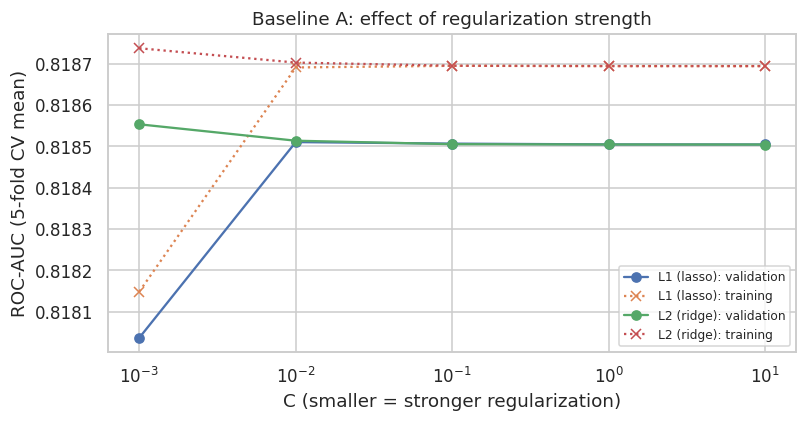

,Penalty,C,mean_train_roc_auc,mean_test_roc_auc,std_test_roc_auc
0,L2 (ridge),0.001,0.8187,0.8186,0.0023
1,L2 (ridge),0.010,0.8187,0.8185,0.0023
2,L1 (lasso),0.010,0.8187,0.8185,0.0023
3,L1 (lasso),0.100,0.8187,0.8185,0.0023
4,L2 (ridge),0.100,0.8187,0.8185,0.0023
5,L1 (lasso),1.000,0.8187,0.8185,0.0023
6,L2 (ridge),1.000,0.8187,0.8185,0.0023
7,L1 (lasso),10.000,0.8187,0.8185,0.0023
8,L2 (ridge),10.000,0.8187,0.8185,0.0023
9,L1 (lasso),0.001,0.8181,0.8180,0.0024


In [6]:
res = pd.DataFrame(search_a.cv_results_)
res['Penalty'] = res['param_model__l1_ratio'].map({0.0: 'L2 (ridge)', 1.0: 'L1 (lasso)'})
res['C'] = res['param_model__C'].astype(float)

fig, ax = plt.subplots(figsize=(7.5, 4))
for pen, g in res.groupby('Penalty'):
    g = g.sort_values('C')
    ax.plot(g['C'], g['mean_test_roc_auc'], marker='o', label=f'{pen}: validation')
    ax.plot(g['C'], g['mean_train_roc_auc'], marker='x', ls=':', label=f'{pen}: training')
ax.set(xscale='log', xlabel='C (smaller = stronger regularization)', ylabel='ROC-AUC (5-fold CV mean)',
       title='Baseline A: effect of regularization strength')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(IMG + 'baseline_regularization.png', bbox_inches='tight'); plt.show()
res[['Penalty', 'C', 'mean_train_roc_auc', 'mean_test_roc_auc', 'std_test_roc_auc']].sort_values('mean_test_roc_auc', ascending=False).round(4).reset_index(drop=True)

**Reading the regularization results:** nine of the ten settings score 0.8185-0.8186; only the strongest L1 setting is slightly lower (0.8180). Training and validation scores are almost identical (0.8187 vs. 0.8186), so the model is **not overfitting**. With 21 weights and about 200,000 training rows, a linear model simply cannot memorize the data. Regularization therefore makes almost no difference here. The best setting (L2, C = 0.001) sits at the edge of the grid, but because the curve is flat, extending the grid would not change the result.

## 5. Baseline B: Adding the Engineered Features

Same model and same grid, now with the 4 engineered features. `BMI_category` is **one-hot encoded** (one yes/no column per WHO band, with "Underweight" as the reference) so each band can have its own effect; the other features are scaled.

In [7]:
numeric_b = original + ['n_conditions', 'lifestyle_score', 'age_x_bmi']
pipe_b = Pipeline([('prep', ColumnTransformer([('num', StandardScaler(), numeric_b),
                                               ('bmi_cat', OneHotEncoder(drop='first'), ['BMI_category'])])),
                   ('model', make_lr())])
t0 = time.time()
search_b = GridSearchCV(pipe_b, param_grid, cv=cv, scoring=scoring, refit='roc_auc', n_jobs=1, return_train_score=True)
search_b.fit(X_train, y_train)
print(f'Baseline B best CV ROC-AUC: {search_b.best_score_:.4f} | best params: {search_b.best_params_} | {time.time()-t0:.0f}s')

rows = []
for name, gs in [('A: 21 original features', search_a), ('B: + engineered features', search_b)]:
    i, r = gs.best_index_, gs.cv_results_
    rows.append({'Baseline': name, 'CV ROC-AUC': r['mean_test_roc_auc'][i], 'std': r['std_test_roc_auc'][i],
                 'CV PR-AUC': r['mean_test_pr_auc'][i], 'CV Recall': r['mean_test_recall'][i], 'CV F1': r['mean_test_f1'][i],
                 'Train ROC-AUC': r['mean_train_roc_auc'][i]})
cv_compare = pd.DataFrame(rows).set_index('Baseline')

# Paired comparison: same folds, so we can look at the fold-by-fold difference
fold_a = np.array([search_a.cv_results_[f'split{k}_test_roc_auc'][search_a.best_index_] for k in range(5)])
fold_b = np.array([search_b.cv_results_[f'split{k}_test_roc_auc'][search_b.best_index_] for k in range(5)])
print('Fold-by-fold ROC-AUC gain from engineered features:', np.round(fold_b - fold_a, 4),
      f'| mean {np.mean(fold_b - fold_a):+.4f}, improved in {(fold_b > fold_a).sum()} of 5 folds')
cv_compare.round(4)

Baseline B best CV ROC-AUC: 0.8201 | best params: {'model__C': 0.01, 'model__l1_ratio': 1.0} | 216s
Fold-by-fold ROC-AUC gain from engineered features: [0.0016 0.0017 0.0009 0.002  0.0016] | mean +0.0016, improved in 5 of 5 folds


,CV ROC-AUC,std,CV PR-AUC,CV Recall,CV F1,Train ROC-AUC
Baseline,,,,,,
A: 21 original features,0.8186,0.0023,0.4381,0.7625,0.4706,0.8187
B: + engineered features,0.8201,0.0022,0.4414,0.7637,0.4735,0.8203


**Do the engineered features help?** Yes, slightly but consistently.

- Cross-validated ROC-AUC rises from **0.8186 to 0.8201 (+0.0016)**, and the gain appears in **all 5 folds** (from +0.0009 to +0.0020). PR-AUC, recall and F1 also improve a little.
- The gain is small because the new features mostly recombine information the model already had. The most likely contributor is the **age × BMI interaction**, which a linear model cannot create on its own.
- Training and validation scores remain almost identical (0.8203 vs. 0.8201), so the extra features did not cause overfitting.
- By the rule set before looking at the test set (keep the features only if they help in every fold), **Baseline B is the chosen baseline.**

## 6. Final Evaluation of the Chosen Baseline on the Test Set
The test set has not been used for any decision so far. We evaluate the chosen baseline (and, for transparency, the other version too) exactly once.

In [8]:
# Pre-set rule (decided on cross-validation, never on the test set): keep the engineered features
# only if they improve ROC-AUC in all 5 folds; otherwise the simpler model wins.
CHOSEN = 'B: + engineered features' if (fold_b > fold_a).all() else 'A: 21 original features'
models = {'A: 21 original features': search_a.best_estimator_, 'B: + engineered features': search_b.best_estimator_}
test_proba = {n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}
final = models[CHOSEN]; p_final = test_proba[CHOSEN]

test_table = pd.DataFrame([dummy_row] + [evaluate(f'Logistic regression {n}', y_test, p) for n, p in test_proba.items()]).set_index('Model')
print('Chosen baseline:', CHOSEN)
test_table.round(3)

Chosen baseline: B: + engineered features


,ROC-AUC,PR-AUC,Recall,Precision,F1,Accuracy
Model,,,,,,
"Always predict ""not at risk""",0.500,0.158,0.000,0.000,0.000,0.842
Logistic regression A: 21 original features,0.818,0.442,0.761,0.342,0.471,0.731
Logistic regression B: + engineered features,0.820,0.447,0.762,0.344,0.474,0.734


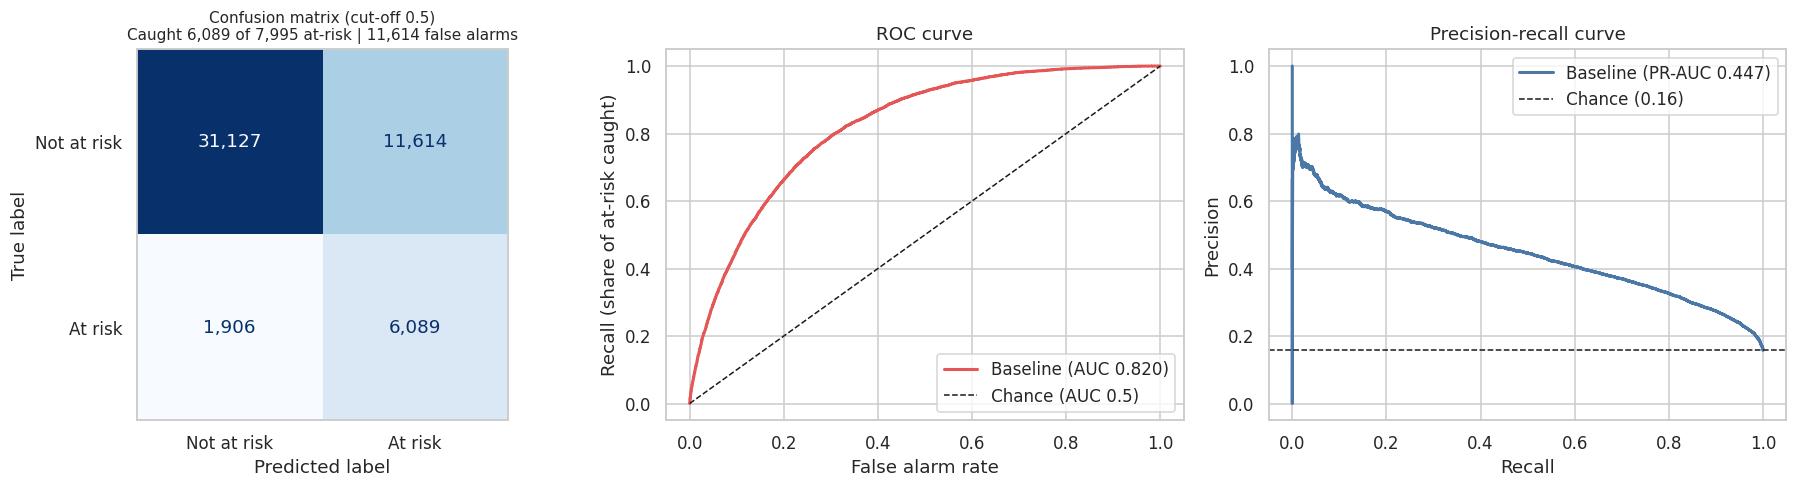

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
cm = confusion_matrix(y_test, (p_final >= 0.5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['Not at risk', 'At risk']).plot(ax=ax[0], cmap='Blues', colorbar=False, values_format=',d')
tn, fp, fn, tp = cm.ravel()
ax[0].set_title(f'Confusion matrix (cut-off 0.5)\nCaught {tp:,} of {tp+fn:,} at-risk | {fp:,} false alarms', fontsize=10)
ax[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, p_final)
ax[1].plot(fpr, tpr, color='#E45756', lw=2, label=f'Baseline (AUC {roc_auc_score(y_test, p_final):.3f})')
ax[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Chance (AUC 0.5)')
ax[1].set(title='ROC curve', xlabel='False alarm rate', ylabel='Recall (share of at-risk caught)'); ax[1].legend(loc='lower right')

prec, rec, _ = precision_recall_curve(y_test, p_final)
ax[2].plot(rec, prec, color='#4C78A8', lw=2, label=f'Baseline (PR-AUC {average_precision_score(y_test, p_final):.3f})')
ax[2].axhline(y_test.mean(), color='k', ls='--', lw=1, label=f'Chance ({y_test.mean():.2f})')
ax[2].set(title='Precision-recall curve', xlabel='Recall', ylabel='Precision'); ax[2].legend()
plt.tight_layout()
plt.savefig(IMG + 'baseline_test_evaluation.png', bbox_inches='tight'); plt.show()

### Reading the test results

- **The baseline clears the do-nothing reference by a wide margin:** ROC-AUC 0.820 vs. 0.5, PR-AUC 0.447 vs. 0.158, and recall 76% vs. 0%.
- **Test scores match cross-validation** (0.820 vs. 0.820), so the model generalizes to unseen people.
- The engineered-feature gain carries over to the test set (0.818 → 0.820).
- **Accuracy (73%) is lower than the do-nothing model's 84%,** which is expected: to catch about three quarters of at-risk people the model must flag many people who turn out not to be at risk.
- **Precision is about 34%:** roughly 2 of every 3 people flagged at the 0.5 cut-off are not at risk according to the survey. Some of these may have undiagnosed prediabetes or diabetes, which the survey cannot record.

## 7. Interpreting the Baseline: Which Factors Raise or Lower Risk?
Each coefficient of a logistic regression converts to an **odds ratio**. Features are standardized, so each odds ratio is the change in the odds of being at risk for a **one standard-deviation increase** in that feature, holding the others fixed (>1 raises risk, <1 lowers it). For the one-hot BMI bands, the odds ratio compares that band with the reference band.

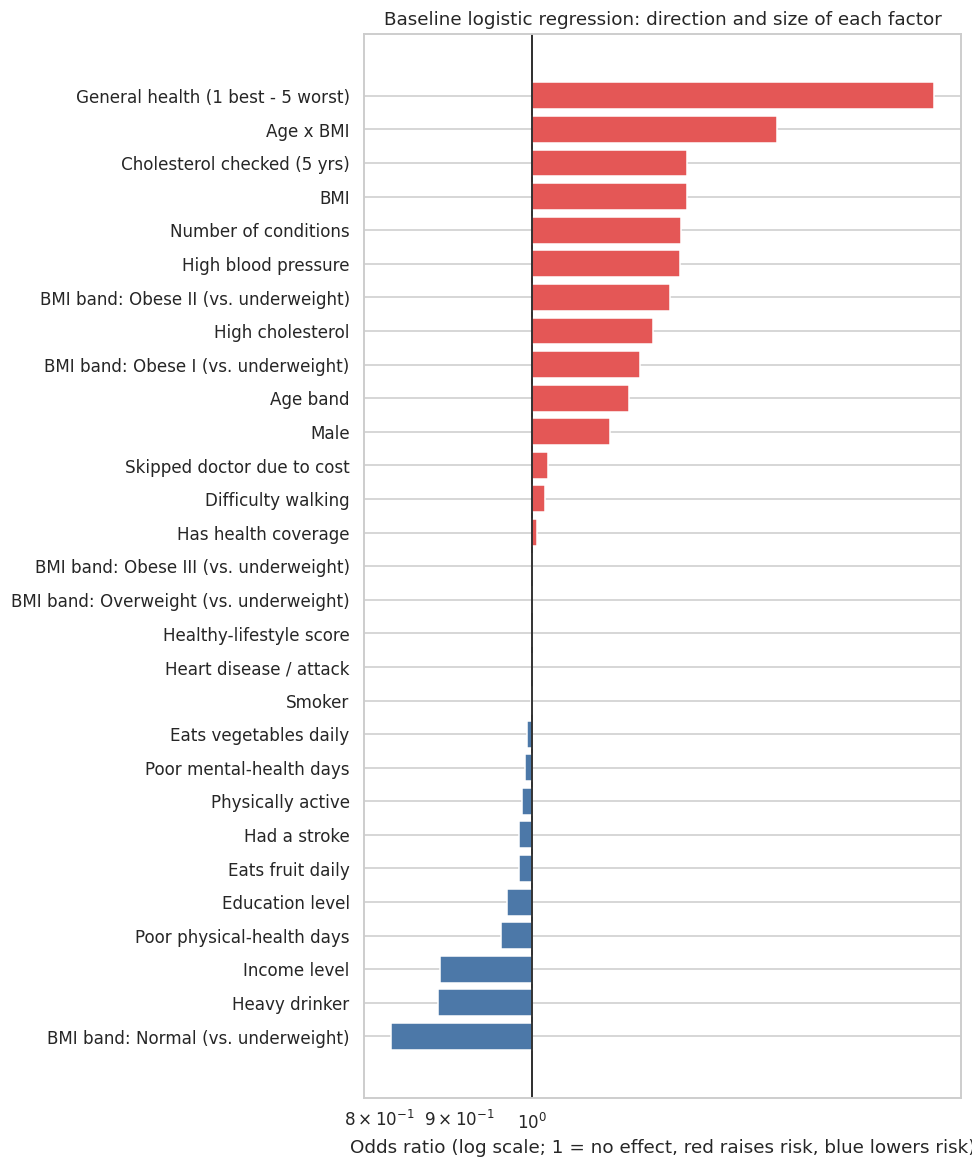

,Feature,Odds ratio
0,General health (1 best - 5 worst),1.79
1,Age x BMI,1.43
2,Cholesterol checked (5 yrs),1.25
3,BMI,1.25
4,Number of conditions,1.24
5,High blood pressure,1.24
6,BMI band: Obese II (vs. underweight),1.22
7,High cholesterol,1.19
8,BMI band: Obese I (vs. underweight),1.17
9,Age band,1.15


In [10]:
nice = {'HighBP': 'High blood pressure', 'HighChol': 'High cholesterol', 'CholCheck': 'Cholesterol checked (5 yrs)', 'BMI': 'BMI',
        'Smoker': 'Smoker', 'Stroke': 'Had a stroke', 'HeartDiseaseorAttack': 'Heart disease / attack', 'PhysActivity': 'Physically active',
        'Fruits': 'Eats fruit daily', 'Veggies': 'Eats vegetables daily', 'HvyAlcoholConsump': 'Heavy drinker', 'AnyHealthcare': 'Has health coverage',
        'NoDocbcCost': 'Skipped doctor due to cost', 'GenHlth': 'General health (1 best - 5 worst)', 'MentHlth': 'Poor mental-health days',
        'PhysHlth': 'Poor physical-health days', 'DiffWalk': 'Difficulty walking', 'Sex': 'Male', 'Age': 'Age band', 'Education': 'Education level',
        'Income': 'Income level', 'n_conditions': 'Number of conditions', 'lifestyle_score': 'Healthy-lifestyle score', 'age_x_bmi': 'Age x BMI'}
bmi_names = ['Underweight', 'Normal', 'Overweight', 'Obese I', 'Obese II', 'Obese III']

names = final.named_steps['prep'].get_feature_names_out()
def pretty(n):
    kind, col = n.split('__', 1)
    if kind == 'bmi_cat':
        return f'BMI band: {bmi_names[int(col.split("_")[-1])]} (vs. underweight)'
    return nice.get(col, col)
odds = pd.DataFrame({'Feature': [pretty(n) for n in names],
                     'Odds ratio': np.exp(final.named_steps['model'].coef_[0])}).sort_values('Odds ratio')

fig, ax = plt.subplots(figsize=(9, 0.32 * len(odds) + 1.5))
ax.barh(odds['Feature'], odds['Odds ratio'] - 1, left=1, color=['#E45756' if v > 1 else '#4C78A8' for v in odds['Odds ratio']])
ax.axvline(1, color='black', lw=1)
ax.set(xscale='log', xlabel='Odds ratio (log scale; 1 = no effect, red raises risk, blue lowers risk)',
       title='Baseline logistic regression: direction and size of each factor')
plt.tight_layout()
plt.savefig(IMG + 'baseline_odds_ratios.png', bbox_inches='tight'); plt.show()
odds.sort_values('Odds ratio', ascending=False).round(2).reset_index(drop=True)

**Reading the odds ratios**

- The strongest effects are **worse self-rated general health** (1.79 per standard deviation), the **age × BMI** interaction (1.43), **BMI**, the **number of conditions** and **high blood pressure** (about 1.24-1.25 each), then high cholesterol (1.19) and age (1.15). Higher **income** (0.87) is associated with lower risk.
- **Caution: individual coefficients are less trustworthy in this model than the predictions.** Several features carry overlapping information (BMI, the BMI bands and age × BMI; high blood pressure and the condition count). When features overlap, the model can split an effect between them in arbitrary ways. The tuned L1 (lasso) penalty also sets some weights to exactly 1.00 (zero effect). That is why, for example, the obese III band shows 1.00 and "normal BMI" shows 0.81 compared with "underweight": the BMI effect is mostly being carried by the BMI and age × BMI columns. Read these as "which group of factors matters", not as precise effects of each one.
- Two effects are reporting artifacts, not causes. **"Cholesterol checked"** raises predicted risk (1.25) because people who see doctors are more likely to be diagnosed. **"Heavy drinker"** looks protective (0.87), most likely because people diagnosed with diabetes are told to cut back on alcohol.

## 8. From Risk Score to Screening Decision
A screening program must pick a cut-off: everyone with a risk score above it is invited for a blood test. To avoid using the test set for this decision, we pick cut-offs from **out-of-fold predictions on the training data** (5-fold `cross_val_predict`), then apply each cut-off once to the test set.

In [11]:
oof = cross_val_predict(clone(final), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
prec_tr, rec_tr, thr_tr = precision_recall_curve(y_train, oof)

rows = []
for target in [0.70, 0.80, 0.90]:
    cutoff = thr_tr[np.where(rec_tr[:-1] >= target)[0].max()]     # highest cut-off reaching the target recall
    pred = (p_final >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'Target recall': f'{target:.0%}', 'Cut-off': round(float(cutoff), 3),
                 'Test recall': round(tp / (tp + fn), 3), 'Test precision': round(tp / (tp + fp), 3),
                 '% of people flagged': round(100 * pred.mean(), 1), 'Tests per case found': round((tp + fp) / tp, 1)})
pd.DataFrame(rows)

,Target recall,Cut-off,Test recall,Test precision,% of people flagged,Tests per case found
0,70%,0.557,0.700,0.370,29.8,2.7
1,80%,0.463,0.797,0.328,38.3,3.0
2,90%,0.333,0.898,0.275,51.5,3.6


**What this means for screening:** with a cut-off of about 0.46, the baseline catches **about 80% of at-risk people** while flagging **38% of the population**, about **3 people tested per case found**. Random selection would need about 6, because the at-risk share is 16%. Aiming for 90% recall means flagging about half the population (3.6 tests per case); settling for 70% recall flags 30% (2.7 per case). The right cut-off depends on the program's testing budget.

## 9. Sensitivity Check: Duplicate Rows
Notebook 1 kept 23,899 duplicate rows because they are different people with identical answers. Here we re-fit the chosen baseline (same settings) on de-duplicated data to check that this choice does not drive the result.

In [12]:
dfd = df.drop_duplicates()
Xd, yd = dfd[original + engineered], dfd['at_risk']
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.20, stratify=yd, random_state=RANDOM_STATE)
m_dedup = clone(final).fit(Xd_tr, yd_tr)
print(f'Test ROC-AUC with duplicates kept:    {roc_auc_score(y_test, p_final):.4f}  ({len(df):,} rows)')
print(f'Test ROC-AUC with duplicates removed: {roc_auc_score(yd_te, m_dedup.predict_proba(Xd_te)[:, 1]):.4f}  ({len(dfd):,} rows)')

Test ROC-AUC with duplicates kept:    0.8202  (253,680 rows)
Test ROC-AUC with duplicates removed: 0.8039  (229,772 rows)


**Interpretation:** removing duplicates lowers the test ROC-AUC by about 0.016 (0.820 → 0.804). The removed rows are mostly very common healthy answer patterns that are easy to classify, so the remaining data is harder on average. This shifts the absolute score but does not change any conclusion. Keeping the duplicates keeps the sample representative of the real population.

## 10. Results Summary and Next Steps

| Model | CV ROC-AUC | Test ROC-AUC | Test PR-AUC | Test recall | Test precision |
|---|---|---|---|---|---|
| Always predict "not at risk" | n/a | 0.500 | 0.158 | 0% | n/a |
| Logistic regression, 21 original features | 0.819 | 0.818 | 0.442 | 76% | 34% |
| **Logistic regression + engineered features (chosen baseline)** | **0.820** | **0.820** | **0.447** | **76%** | **34%** |

**Findings so far**
1. A simple, tuned logistic regression already ranks people by risk correctly about **82% of the time** (ROC-AUC 0.820).
2. **Feature engineering gives a small, consistent improvement** (+0.002 ROC-AUC, in every cross-validation fold).
3. The model is **not overfitting**, and regularization barely matters.
4. The strongest signals are general health, BMI (and its interaction with age), the number of cardiometabolic conditions, high blood pressure, high cholesterol and age.
5. As a screening aid, a cut-off can catch about 80% of at-risk people for about 3 tests per case found.

**Next steps (Module 24)**
- Train **random forest, gradient boosting and a deep neural network**, tuned with cross-validation, and compare them with this baseline on the same test set.
- Test whether the more flexible models can learn the interactions that feature engineering only partly captured.
- Add uncertainty estimates (bootstrap confidence intervals) to tell real differences from noise.
- Check performance by age, sex and income group (fairness), and choose the screening cut-off.
- Polish the notebooks and README for technical and non-technical readers.